# Experimento de Data Augmentation — Jittering + Modelo Generativo Tabular (Gaussian Copula)

Este notebook substitui o **block bootstrap** (cenário C original) por um **modelo generativo tabular** (SDV `GaussianCopulaSynthesizer`), mantendo o **jittering climático** exatamente como estava.

**Por que trocar o block bootstrap?**
Block bootstrap reamostra blocos de dias consecutivos, mas ao concatenar blocos de períodos diferentes (ex: um bloco de fim de férias com um bloco de meio de semestre normal) a variedade adicional é limitada e ainda existe risco de combinações de calendário/cardápio implausíveis nas fronteiras entre blocos.

**Como funciona a nova abordagem (Gaussian Copula + âncora de calendário):**
1. O bloco de colunas de **calendário** (`Ano`, `Mês`, `Dia_mês`, `Dia_semana`, `letivo`, `feriado`, `ferias`, `vespera_*`, `pos_*`, `dias_*`) é **sempre reamostrado de combinações reais** (do próprio treino ou do `calendario.csv` completo) — isso garante 100% de coerência lógica, já que são valores determinísticos derivados da data.
2. Uma **cópula gaussiana implementada manualmente** (só `numpy`/`scipy`/`pandas`, sem `sdv`/`torch`) é ajustada nos dados reais de treino e gera, **condicionado a essa âncora de calendário**, o restante das colunas: cardápio (`prato_principal_1/2`, `guarnição`, `sobremesa_1`, `refeicao`), clima e o alvo `total`. A amostragem condicional usa a fórmula analítica de normal multivariada condicional (complemento de Schur), então preserva a correlação conjunta com precisão, sem depender de nenhuma biblioteca pesada de terceiros.
3. Os mesmos *sanity checks* de clima usados no jittering (precipitação ≥ 0, umidade em [0, 100], `Temp_min ≤ Temp_max`) são aplicados às linhas sintéticas.

Cenários testados:
- **A. Baseline** — sem aumento de dados
- **B. Só jittering** — ruído gaussiano no clima (igual ao script original)
- **C. Só modelo generativo (Gaussian Copula)** — substitui o block bootstrap
- **D. Combinado** — jittering + modelo generativo

A calibração conformal (`X_calib`/`y_calib`) e o holdout final **nunca** recebem dados sintéticos — só o conjunto de treino é aumentado, exatamente como no experimento original.

In [ ]:
# Esta técnica NÃO depende mais de sdv/torch (evita o erro de DLL do PyTorch no Windows).
# scipy já é dependência padrão de qualquer instalação com scikit-learn, mas garantimos aqui.
%pip install --quiet scipy

In [1]:
from __future__ import annotations

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")  # a SDV é bem verbosa com warnings de amostragem condicional

np.random.seed(42)

In [15]:
BASE_DIR = Path(os.getcwd())
OUTPUT_DIR = BASE_DIR / "resultados_experimento"
OUTPUT_DIR.mkdir(exist_ok=True)

CONFIG = {
    "area1": {
        "csv_path": "projeto-ru\previsao\data\dataarea1.csv",
        "onehot_cols": [
            "Mês", "Dia_semana", "Dia_mês", "prato_principal_1",
            "prato_principal_2", "guarnição", "sobremesa_1", "refeicao",
        ],
        "remove_cafe_da_manha": True,
        "dropna": True,
        "remove_total_zero": True,
    },
    "area2": {
        "csv_path": "projeto-ru\previsao\data\dataarea2.csv",
        "onehot_cols": [
            "Mês", "Dia_semana", "Dia_mês", "prato_principal_1",
            "prato_principal_2", "guarnição", "sobremesa_1",
        ],
        "remove_cafe_da_manha": False,
        "dropna": False,
        "remove_total_zero": False,
    },
}

CLIMATE_COLS = [
    "Precipitacao_mm", "Temp_max_C", "Temp_min_C",
    "Umid_rel_ar", "Vento_velocidade_ms", "Vento_rajada_maxima_ms",
]

# Colunas de calendário: sempre determinísticas em função da data, então
# nunca são "inventadas" pelo gerador — apenas reamostradas de combinações reais.
DATE_COLS = [
    "Ano", "Mês", "Dia_mês", "Dia_semana", "letivo", "feriado", "ferias",
    "vespera_nao_letivo", "pos_nao_letivo", "vespera_feriado", "pos_feriado",
    "dias_desde_inicio_ferias", "dias_desde_ultimas_ferias",
    "dias_ate_ferias", "dias_ate_feriado",
]

COLUNAS_FILTRO_RARO = ["guarnição", "prato_principal_1", "prato_principal_2", "sobremesa_1"]

In [16]:
def _resolver_caminho(nomes_possiveis, bases):
    for base in bases:
        for nome in nomes_possiveis:
            candidato = base / nome
            if candidato.exists():
                return candidato
    return None


def _bases_padrao():
    return [
        BASE_DIR,
        BASE_DIR / "data",
        BASE_DIR.parent,
        BASE_DIR.parent / "data",
        BASE_DIR.parent.parent / "data" / "data_treatment_completo",
    ]


def carregar_dados(area: str):
    """Reproduz o pré-processamento de Previsao_areaX.ipynb."""
    cfg = CONFIG[area]
    nomes = [Path(cfg["csv_path"]).name, f"data{area}.csv", f"data_{area}.csv"]
    caminho = _resolver_caminho(nomes, _bases_padrao())
    if caminho is None:
        raise FileNotFoundError(
            f"Não encontrei o CSV da {area}. Coloque este notebook na mesma pasta "
            f"dos scripts de cenário originais (ou ajuste CONFIG['{area}']['csv_path'])."
        )
    data = pd.read_csv(caminho, header=0)

    if cfg["remove_cafe_da_manha"]:
        data = data[data["refeicao"] != "cafe da manha"].copy()
    if cfg["dropna"]:
        data = data.dropna()
    if cfg["remove_total_zero"]:
        data = data[data["total"] != 0]

    for col in COLUNAS_FILTRO_RARO:
        data = data.groupby(col).filter(lambda x: len(x) >= 5)

    data_raw_base = data.reset_index(drop=True).copy()
    data_onehot = pd.get_dummies(data_raw_base, columns=cfg["onehot_cols"])

    atributos = data_onehot.drop(columns=["total"]).columns
    X = data_onehot[atributos]
    y = data_onehot["total"]
    return data_raw_base, X, y


def carregar_calendario_completo():
    """
    Carrega calendario.csv (se existir) para servir de "pool" de âncoras de
    calendário mais diverso do que apenas as datas presentes no treino.
    Se não encontrar, retorna None — a função de aumento cai de volta para
    usar as datas do próprio treino como âncora.
    """
    caminho = _resolver_caminho(["calendario.csv"], _bases_padrao())
    if caminho is None:
        print("Aviso: calendario.csv não encontrado — âncoras de calendário virão só do treino.")
        return None
    return pd.read_csv(caminho)

## Técnica B — Jittering climático (sem alteração)

Ruído gaussiano nas colunas contínuas de clima, com desvio-padrão calculado por mês (respeita a sazonalidade), mais os mesmos *sanity checks* de faixa válida usados no notebook de tratamento de dados.

In [17]:
def jitter_climatico(X_train, y_train, meta_train, n_copias=2, escala_ruido=0.15, seed=42):
    """
    Gera cópias sintéticas de X_train/y_train com ruído gaussiano nas
    colunas climáticas contínuas. O desvio-padrão do ruído é calculado
    POR MÊS (usando meta_train['Mês']), para respeitar a sazonalidade.
    """
    rng = np.random.default_rng(seed)
    meses = meta_train["Mês"]

    std_por_mes = {}
    for col in CLIMATE_COLS:
        if col not in X_train.columns:
            continue
        std_local = X_train[col].groupby(meses).transform("std")
        std_global = X_train[col].std()
        std_por_mes[col] = std_local.fillna(std_global)

    copias_X, copias_y = [], []
    for _ in range(n_copias):
        X_sint = X_train.copy()
        for col, sigma_series in std_por_mes.items():
            sigma = sigma_series.to_numpy()
            ruido = rng.normal(loc=0.0, scale=np.clip(sigma, 1e-6, None) * escala_ruido)
            X_sint[col] = X_sint[col].to_numpy() + ruido

        if "Precipitacao_mm" in X_sint.columns:
            X_sint["Precipitacao_mm"] = X_sint["Precipitacao_mm"].clip(lower=0)
        if "Umid_rel_ar" in X_sint.columns:
            X_sint["Umid_rel_ar"] = X_sint["Umid_rel_ar"].clip(0, 100)
        if {"Temp_min_C", "Temp_max_C"}.issubset(X_sint.columns):
            inconsistente = X_sint["Temp_min_C"] > X_sint["Temp_max_C"]
            if inconsistente.any():
                tmp = X_sint.loc[inconsistente, "Temp_min_C"].copy()
                X_sint.loc[inconsistente, "Temp_min_C"] = X_sint.loc[inconsistente, "Temp_max_C"]
                X_sint.loc[inconsistente, "Temp_max_C"] = tmp

        copias_X.append(X_sint)
        copias_y.append(y_train.copy())

    X_jitter = pd.concat(copias_X, ignore_index=True)
    y_jitter = pd.concat(copias_y, ignore_index=True)
    return X_jitter, y_jitter

## Técnica C — Cópula gaussiana manual (sem `sdv`/`torch`), no lugar do block bootstrap

Implementação própria (`CopulaGaussianManual`), sem nenhuma dependência de `sdv`/`ctgan`/`torch` — resolve o problema de instalação/DLL no Windows.

Como funciona:
1. Cada coluna é transformada em um "score normal" (transformação de cópula): colunas contínuas via posto empírico (`rank`) → `norm.ppf`; colunas categóricas via intervalo de probabilidade acumulada da categoria → `norm.ppf`.
2. Calcula a matriz de correlação conjunta desses scores normais (essa é a "cópula").
3. Para gerar uma linha sintética, fixamos os scores das colunas de **calendário** (a âncora real) e usamos a fórmula analítica de **normal multivariada condicional** (complemento de Schur) para sortear os scores das colunas restantes (clima, cardápio, `total`), respeitando a correlação aprendida.
4. Cada score sorteado é transformado de volta à escala original: contínuo via interpolação na distribuição empírica de treino; categórico via a categoria cujo intervalo de probabilidade acumulada contém o score.
5. Os mesmos *sanity checks* de clima do jittering são aplicados no final.

In [18]:
from scipy.stats import norm


def _normal_score_continua(serie):
    n = len(serie)
    ranks = serie.rank(method="average").to_numpy()
    u = np.clip(ranks / (n + 1), 1e-6, 1 - 1e-6)
    return norm.ppf(u)


def _ajustar_marginal_categorica(serie):
    freqs = serie.value_counts(normalize=True)
    categorias = freqs.index.tolist()
    cum_probs = np.concatenate([[0.0], np.cumsum(freqs.to_numpy())])
    return categorias, cum_probs


def _normal_score_categorica(serie, categorias, cum_probs, rng):
    limites = {cat: (cum_probs[i], cum_probs[i + 1]) for i, cat in enumerate(categorias)}
    u = np.array([rng.uniform(*limites[v]) for v in serie])
    u = np.clip(u, 1e-6, 1 - 1e-6)
    return norm.ppf(u)


class CopulaGaussianManual:
    """
    Implementação leve de cópula gaussiana (sem sdv/torch), com amostragem
    CONDICIONAL analítica (fórmula de normal multivariada condicional /
    complemento de Schur) — usada para condicionar clima, cardápio e total
    nas colunas de calendário reais (a "âncora").
    """

    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.colunas_continuas = []
        self.colunas_categoricas = []
        self.colunas_ordem = []
        self.marginais_continuas = {}
        self.marginais_categoricas = {}
        self.corr = None

    def fit(self, df, colunas_continuas, colunas_categoricas):
        self.colunas_continuas = [c for c in colunas_continuas if c in df.columns]
        self.colunas_categoricas = [c for c in colunas_categoricas if c in df.columns]
        self.colunas_ordem = self.colunas_continuas + self.colunas_categoricas

        colunas_z = {}
        for col in self.colunas_continuas:
            self.marginais_continuas[col] = np.sort(df[col].to_numpy())
            colunas_z[col] = _normal_score_continua(df[col])
        for col in self.colunas_categoricas:
            categorias, cum_probs = _ajustar_marginal_categorica(df[col])
            self.marginais_categoricas[col] = (categorias, cum_probs)
            colunas_z[col] = _normal_score_categorica(df[col], categorias, cum_probs, self.rng)

        Z = pd.DataFrame(colunas_z)[self.colunas_ordem]
        corr = Z.corr().to_numpy()
        corr = np.nan_to_num(corr, nan=0.0)
        np.fill_diagonal(corr, 1.0)
        self.corr = corr + np.eye(len(self.colunas_ordem)) * 1e-6  # regularização numérica
        return self

    def _valor_para_z(self, col, valor):
        if col in self.marginais_continuas:
            valores_ordenados = self.marginais_continuas[col]
            u = np.searchsorted(valores_ordenados, valor) / len(valores_ordenados)
        else:
            categorias, cum_probs = self.marginais_categoricas[col]
            try:
                idx = categorias.index(valor)
            except ValueError:
                idx = 0  # categoria não vista no treino: aproxima pela mais comum
            u = (cum_probs[idx] + cum_probs[idx + 1]) / 2
        u = np.clip(u, 1e-6, 1 - 1e-6)
        return norm.ppf(u)

    def _z_para_valor(self, col, u):
        if col in self.marginais_continuas:
            valores_ordenados = self.marginais_continuas[col]
            idx = np.clip((u * len(valores_ordenados)).astype(int), 0, len(valores_ordenados) - 1)
            return valores_ordenados[idx]
        categorias, cum_probs = self.marginais_categoricas[col]
        idx = np.clip(np.searchsorted(cum_probs, u, side="right") - 1, 0, len(categorias) - 1)
        return np.array(categorias)[idx]

    def amostrar_condicional(self, ancoras_df, colunas_conhecidas):
        colunas_conhecidas = [c for c in colunas_conhecidas if c in self.colunas_ordem]
        colunas_alvo = [c for c in self.colunas_ordem if c not in colunas_conhecidas]

        idx_k = [self.colunas_ordem.index(c) for c in colunas_conhecidas]
        idx_u = [self.colunas_ordem.index(c) for c in colunas_alvo]

        sigma_kk = self.corr[np.ix_(idx_k, idx_k)]
        sigma_uu = self.corr[np.ix_(idx_u, idx_u)]
        sigma_uk = self.corr[np.ix_(idx_u, idx_k)]
        sigma_kk_inv = np.linalg.pinv(sigma_kk)

        cov_cond = sigma_uu - sigma_uk @ sigma_kk_inv @ sigma_uk.T
        cov_cond = (cov_cond + cov_cond.T) / 2  # garante simetria numérica
        cov_cond += np.eye(len(idx_u)) * 1e-6

        n = len(ancoras_df)
        Z_conhecido = np.column_stack([
            np.array([self._valor_para_z(col, v) for v in ancoras_df[col]])
            for col in colunas_conhecidas
        ])
        media_cond = Z_conhecido @ sigma_kk_inv @ sigma_uk.T  # shape (n, len(idx_u))

        ruido = self.rng.multivariate_normal(mean=np.zeros(len(idx_u)), cov=cov_cond, size=n)
        Z_alvo = media_cond + ruido
        U_alvo = norm.cdf(Z_alvo)

        resultado = ancoras_df.copy().reset_index(drop=True)
        for i, col in enumerate(colunas_alvo):
            resultado[col] = self._z_para_valor(col, U_alvo[:, i])
        return resultado


def sdv_augment(meta_train, x_columns, cfg, area, n_synthetic=None,
                 calendario_completo=None, seed=42):
    """
    Mantém o mesmo nome/assinatura usado no restante do notebook (tipo "sdv"
    em aplicar_aumentos), mas a implementação agora é 100% local — sem sdv,
    sem ctgan, sem torch.
    """
    if n_synthetic is None:
        n_synthetic = len(meta_train)

    date_cols = [c for c in DATE_COLS if c in meta_train.columns]
    colunas_categoricas_conteudo = ["prato_principal_1", "prato_principal_2", "guarni\u00e7\u00e3o", "sobremesa_1"]
    if area == "area1":
        colunas_categoricas_conteudo.append("refeicao")
    colunas_continuas_conteudo = [c for c in CLIMATE_COLS if c in meta_train.columns] + ["total"]

    colunas_continuas = colunas_continuas_conteudo
    colunas_categoricas = date_cols + colunas_categoricas_conteudo

    modelo = CopulaGaussianManual(seed=seed).fit(meta_train, colunas_continuas, colunas_categoricas)

    pool_datas = calendario_completo if calendario_completo is not None else meta_train
    pool_datas = pool_datas[date_cols].drop_duplicates()
    ancoras = pool_datas.sample(
        n=n_synthetic, replace=True, random_state=np.random.RandomState(seed)
    ).reset_index(drop=True)

    sintetico = modelo.amostrar_condicional(ancoras, colunas_conhecidas=date_cols)

    # Sanity checks (mesmos usados no jittering)
    if "Precipitacao_mm" in sintetico.columns:
        sintetico["Precipitacao_mm"] = sintetico["Precipitacao_mm"].clip(lower=0)
    if "Umid_rel_ar" in sintetico.columns:
        sintetico["Umid_rel_ar"] = sintetico["Umid_rel_ar"].clip(0, 100)
    if {"Temp_min_C", "Temp_max_C"}.issubset(sintetico.columns):
        inconsistente = sintetico["Temp_min_C"] > sintetico["Temp_max_C"]
        if inconsistente.any():
            tmp = sintetico.loc[inconsistente, "Temp_min_C"].copy()
            sintetico.loc[inconsistente, "Temp_min_C"] = sintetico.loc[inconsistente, "Temp_max_C"]
            sintetico.loc[inconsistente, "Temp_max_C"] = tmp
    if "total" in sintetico.columns:
        sintetico["total"] = sintetico["total"].clip(lower=0)

    sintetico_onehot = pd.get_dummies(sintetico, columns=cfg["onehot_cols"])
    X_sint = sintetico_onehot.reindex(columns=x_columns, fill_value=0).reset_index(drop=True)
    y_sint = sintetico["total"].astype(float).reset_index(drop=True)
    return X_sint, y_sint

## Combinando as técnicas e o loop de experimento

`aplicar_aumentos` recebe uma lista de aumentos a aplicar (`jitter`, `sdv`, ambos, ou nenhum) e devolve o treino aumentado. `rodar_experimento` repete o treino/calibração/holdout N vezes com sementes diferentes para dar robustez estatística à comparação — igual ao experimento original.

In [19]:
def aplicar_aumentos(X_train, y_train, meta_train, aumentos, area, cfg,
                      calendario_completo, seed):
    partes_X, partes_y = [X_train], [y_train]
    for aumento in aumentos:
        tipo = aumento["tipo"]
        kwargs = aumento.get("kwargs", {})
        if tipo == "jitter":
            X_a, y_a = jitter_climatico(X_train, y_train, meta_train, seed=seed, **kwargs)
        elif tipo == "sdv":
            X_a, y_a = sdv_augment(
                meta_train, X_train.columns, cfg, area,
                calendario_completo=calendario_completo, seed=seed, **kwargs,
            )
        else:
            raise ValueError(f"Tipo de aumento desconhecido: {tipo}")
        partes_X.append(X_a)
        partes_y.append(y_a)

    X_final = pd.concat(partes_X, ignore_index=True)
    y_final = pd.concat(partes_y, ignore_index=True)
    return X_final, y_final


def rodar_experimento(X, y, data_raw_base, aumentos, area, cfg,
                       calendario_completo=None, n_repeticoes=15, alpha=0.05,
                       test_size=0.3, holdout_size=0.15, verbose=True):
    resultados = []
    for seed in range(n_repeticoes):
        X_resto, X_holdout, y_resto, y_holdout = train_test_split(
            X, y, test_size=holdout_size, random_state=seed
        )
        X_train, X_calib, y_train, y_calib = train_test_split(
            X_resto, y_resto, test_size=test_size, random_state=seed
        )
        meta_train = data_raw_base.loc[X_train.index]

        if aumentos:
            X_train_final, y_train_final = aplicar_aumentos(
                X_train, y_train, meta_train, aumentos, area, cfg,
                calendario_completo, seed,
            )
        else:
            X_train_final, y_train_final = X_train, y_train

        modelo = VotingRegressor(
            estimators=[
                ("gb", GradientBoostingRegressor(n_estimators=100, random_state=seed)),
                ("rf", RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1)),
            ],
            weights=[3, 1],
        )
        modelo.fit(X_train_final, y_train_final)

        residuos_calib = np.abs(y_calib.to_numpy() - modelo.predict(X_calib))
        margem = float(np.quantile(residuos_calib, 1 - alpha, method="higher"))

        residuos_holdout = np.abs(y_holdout.to_numpy() - modelo.predict(X_holdout))
        cobertura_real = float((residuos_holdout <= margem).mean())

        linha = {
            "seed": seed,
            "n_treino_final": len(X_train_final),
            "mae": float(residuos_calib.mean()),
            "margem": margem,
            "cobertura_holdout": cobertura_real,
        }
        resultados.append(linha)

        if verbose:
            print(
                f"  seed={seed:2d}  n_treino={linha['n_treino_final']:5d}  "
                f"MAE={linha['mae']:7.2f}  margem={linha['margem']:7.2f}  "
                f"cobertura_holdout={linha['cobertura_holdout']:.3f}",
                flush=True,
            )

    return pd.DataFrame(resultados)

## Configuração do experimento

Ajuste `AREA` e `N_REPETICOES` aqui. Mantenha os mesmos valores em todos os cenários abaixo para a comparação fazer sentido.

In [20]:
AREA = "area1"          # 'area1' ou 'area2'
N_REPETICOES = 15       # reduza para ~5 num teste rápido

N_COPIAS_JITTER = 2
ESCALA_RUIDO = 0.20

N_SINTETICOS = None      # None = mesmo tamanho do treino em cada repetição

cfg = CONFIG[AREA]
data_raw_base, X, y = carregar_dados(AREA)
calendario_completo = carregar_calendario_completo()

print(f"Área: {AREA}")
print(f"Observações: {len(X)}  |  Atributos: {X.shape[1]}")

Área: area1
Observações: 1444  |  Atributos: 195


## Cenário A — Baseline (sem aumento)

In [21]:
print("=== Cenário A: Baseline ===\n")
resultados_A = rodar_experimento(
    X, y, data_raw_base, aumentos=[], area=AREA, cfg=cfg,
    calendario_completo=calendario_completo, n_repeticoes=N_REPETICOES,
)
resultados_A["cenario"] = "A_baseline"
resultados_A["area"] = AREA
resultados_A.to_csv(OUTPUT_DIR / f"resultados_cenario_A_{AREA}.csv", index=False)
resultados_A[["mae", "margem", "cobertura_holdout"]].describe()

=== Cenário A: Baseline ===

  seed= 0  n_treino=  858  MAE= 137.46  margem= 370.85  cobertura_holdout=0.949
  seed= 1  n_treino=  858  MAE= 130.68  margem= 362.44  cobertura_holdout=0.940
  seed= 2  n_treino=  858  MAE= 131.61  margem= 345.65  cobertura_holdout=0.922
  seed= 3  n_treino=  858  MAE= 137.13  margem= 418.09  cobertura_holdout=0.972
  seed= 4  n_treino=  858  MAE= 127.60  margem= 326.20  cobertura_holdout=0.899
  seed= 5  n_treino=  858  MAE= 139.97  margem= 405.77  cobertura_holdout=0.968
  seed= 6  n_treino=  858  MAE= 125.36  margem= 328.34  cobertura_holdout=0.922
  seed= 7  n_treino=  858  MAE= 123.30  margem= 346.54  cobertura_holdout=0.963
  seed= 8  n_treino=  858  MAE= 134.06  margem= 376.94  cobertura_holdout=0.945
  seed= 9  n_treino=  858  MAE= 140.11  margem= 345.14  cobertura_holdout=0.963
  seed=10  n_treino=  858  MAE= 141.44  margem= 375.45  cobertura_holdout=0.949
  seed=11  n_treino=  858  MAE= 137.21  margem= 359.48  cobertura_holdout=0.945
  seed=12  

,mae,margem,cobertura_holdout
count,15.000000,15.000000,15.000000
mean,133.038063,361.788200,0.945622
std,6.085563,27.969112,0.022251
min,122.963762,320.791135,0.898618
25%,129.137392,345.398396,0.930876
50%,134.061926,360.843944,0.949309
75%,137.333536,376.194480,0.963134
max,141.441801,418.092455,0.972350


## Cenário B — Só jittering climático

In [22]:
print("=== Cenário B: Só jittering ===\n")
resultados_B = rodar_experimento(
    X, y, data_raw_base,
    aumentos=[{"tipo": "jitter", "kwargs": {"n_copias": N_COPIAS_JITTER, "escala_ruido": ESCALA_RUIDO}}],
    area=AREA, cfg=cfg, calendario_completo=calendario_completo, n_repeticoes=N_REPETICOES,
)
resultados_B["cenario"] = "B_jittering"
resultados_B["area"] = AREA
resultados_B.to_csv(OUTPUT_DIR / f"resultados_cenario_B_{AREA}.csv", index=False)
resultados_B[["mae", "margem", "cobertura_holdout"]].describe()

=== Cenário B: Só jittering ===

  seed= 0  n_treino= 2574  MAE= 134.88  margem= 364.25  cobertura_holdout=0.945
  seed= 1  n_treino= 2574  MAE= 128.74  margem= 362.26  cobertura_holdout=0.949
  seed= 2  n_treino= 2574  MAE= 129.02  margem= 331.48  cobertura_holdout=0.912
  seed= 3  n_treino= 2574  MAE= 136.13  margem= 406.02  cobertura_holdout=0.972
  seed= 4  n_treino= 2574  MAE= 125.44  margem= 324.58  cobertura_holdout=0.899
  seed= 5  n_treino= 2574  MAE= 137.61  margem= 399.70  cobertura_holdout=0.968
  seed= 6  n_treino= 2574  MAE= 122.96  margem= 329.80  cobertura_holdout=0.926
  seed= 7  n_treino= 2574  MAE= 121.70  margem= 347.12  cobertura_holdout=0.972
  seed= 8  n_treino= 2574  MAE= 132.94  margem= 368.09  cobertura_holdout=0.931
  seed= 9  n_treino= 2574  MAE= 137.92  margem= 347.89  cobertura_holdout=0.963
  seed=10  n_treino= 2574  MAE= 138.75  margem= 349.95  cobertura_holdout=0.940
  seed=11  n_treino= 2574  MAE= 135.53  margem= 357.51  cobertura_holdout=0.945
  seed=

,mae,margem,cobertura_holdout
count,15.000000,15.000000,15.000000
mean,131.057638,356.210511,0.944086
std,5.976344,23.750978,0.023164
min,121.481929,324.583657,0.898618
25%,127.089881,339.980356,0.928571
50%,132.077922,351.041184,0.944700
75%,135.827092,366.173239,0.965438
max,138.746389,406.022455,0.972350


## Cenário C — Só modelo generativo (Gaussian Copula), no lugar do block bootstrap

In [23]:
print("=== Cenário C: Só Gaussian Copula ===\n")
resultados_C = rodar_experimento(
    X, y, data_raw_base,
    aumentos=[{"tipo": "sdv", "kwargs": {"n_synthetic": N_SINTETICOS}}],
    area=AREA, cfg=cfg, calendario_completo=calendario_completo, n_repeticoes=N_REPETICOES,
)
resultados_C["cenario"] = "C_sdv_copula"
resultados_C["area"] = AREA
resultados_C.to_csv(OUTPUT_DIR / f"resultados_cenario_C_{AREA}.csv", index=False)
resultados_C[["mae", "margem", "cobertura_holdout"]].describe()

=== Cenário C: Só Gaussian Copula ===

  seed= 0  n_treino= 1716  MAE= 229.33  margem= 596.09  cobertura_holdout=0.959
  seed= 1  n_treino= 1716  MAE= 232.10  margem= 562.91  cobertura_holdout=0.931
  seed= 2  n_treino= 1716  MAE= 229.81  margem= 538.94  cobertura_holdout=0.926
  seed= 3  n_treino= 1716  MAE= 232.10  margem= 608.39  cobertura_holdout=0.977
  seed= 4  n_treino= 1716  MAE= 241.25  margem= 595.87  cobertura_holdout=0.931
  seed= 5  n_treino= 1716  MAE= 214.30  margem= 545.96  cobertura_holdout=0.935
  seed= 6  n_treino= 1716  MAE= 223.21  margem= 539.83  cobertura_holdout=0.922
  seed= 7  n_treino= 1716  MAE= 217.18  margem= 545.85  cobertura_holdout=0.959
  seed= 8  n_treino= 1716  MAE= 234.01  margem= 565.26  cobertura_holdout=0.945
  seed= 9  n_treino= 1716  MAE= 239.19  margem= 551.79  cobertura_holdout=0.959
  seed=10  n_treino= 1716  MAE= 235.97  margem= 585.20  cobertura_holdout=0.945
  seed=11  n_treino= 1716  MAE= 218.73  margem= 505.94  cobertura_holdout=0.940
 

,mae,margem,cobertura_holdout
count,15.000000,15.000000,15.000000
mean,226.950660,559.044239,0.941014
std,10.851878,37.591308,0.024767
min,207.023331,480.837096,0.870968
25%,217.954734,541.978915,0.930876
50%,229.812310,551.792002,0.944700
75%,234.991122,590.534496,0.958525
max,241.249841,618.652566,0.976959


## Cenário D — Jittering + modelo generativo (combinado)

In [24]:
print("=== Cenário D: Jittering + Gaussian Copula ===\n")
resultados_D = rodar_experimento(
    X, y, data_raw_base,
    aumentos=[
        {"tipo": "jitter", "kwargs": {"n_copias": N_COPIAS_JITTER, "escala_ruido": ESCALA_RUIDO}},
        {"tipo": "sdv", "kwargs": {"n_synthetic": N_SINTETICOS}},
    ],
    area=AREA, cfg=cfg, calendario_completo=calendario_completo, n_repeticoes=N_REPETICOES,
)
resultados_D["cenario"] = "D_combinado"
resultados_D["area"] = AREA
resultados_D.to_csv(OUTPUT_DIR / f"resultados_cenario_D_{AREA}.csv", index=False)
resultados_D[["mae", "margem", "cobertura_holdout"]].describe()

=== Cenário D: Jittering + Gaussian Copula ===

  seed= 0  n_treino= 3432  MAE= 184.27  margem= 484.85  cobertura_holdout=0.940
  seed= 1  n_treino= 3432  MAE= 177.11  margem= 465.21  cobertura_holdout=0.931
  seed= 2  n_treino= 3432  MAE= 181.64  margem= 491.98  cobertura_holdout=0.968
  seed= 3  n_treino= 3432  MAE= 186.09  margem= 511.74  cobertura_holdout=0.972
  seed= 4  n_treino= 3432  MAE= 189.56  margem= 479.13  cobertura_holdout=0.940
  seed= 5  n_treino= 3432  MAE= 175.32  margem= 454.34  cobertura_holdout=0.949
  seed= 6  n_treino= 3432  MAE= 172.28  margem= 455.72  cobertura_holdout=0.931
  seed= 7  n_treino= 3432  MAE= 176.54  margem= 443.61  cobertura_holdout=0.949
  seed= 8  n_treino= 3432  MAE= 190.96  margem= 470.82  cobertura_holdout=0.945
  seed= 9  n_treino= 3432  MAE= 187.25  margem= 451.96  cobertura_holdout=0.959
  seed=10  n_treino= 3432  MAE= 187.38  margem= 481.99  cobertura_holdout=0.954
  seed=11  n_treino= 3432  MAE= 175.74  margem= 463.96  cobertura_holdou

,mae,margem,cobertura_holdout
count,15.000000,15.000000,15.000000
mean,180.390889,468.678936,0.949002
std,8.257146,25.909713,0.016008
min,165.081865,410.911735,0.917051
25%,175.527142,454.741838,0.940092
50%,181.638761,465.205537,0.949309
75%,187.318509,483.416042,0.963134
max,190.956355,511.743165,0.972350


## Comparação final entre os cenários

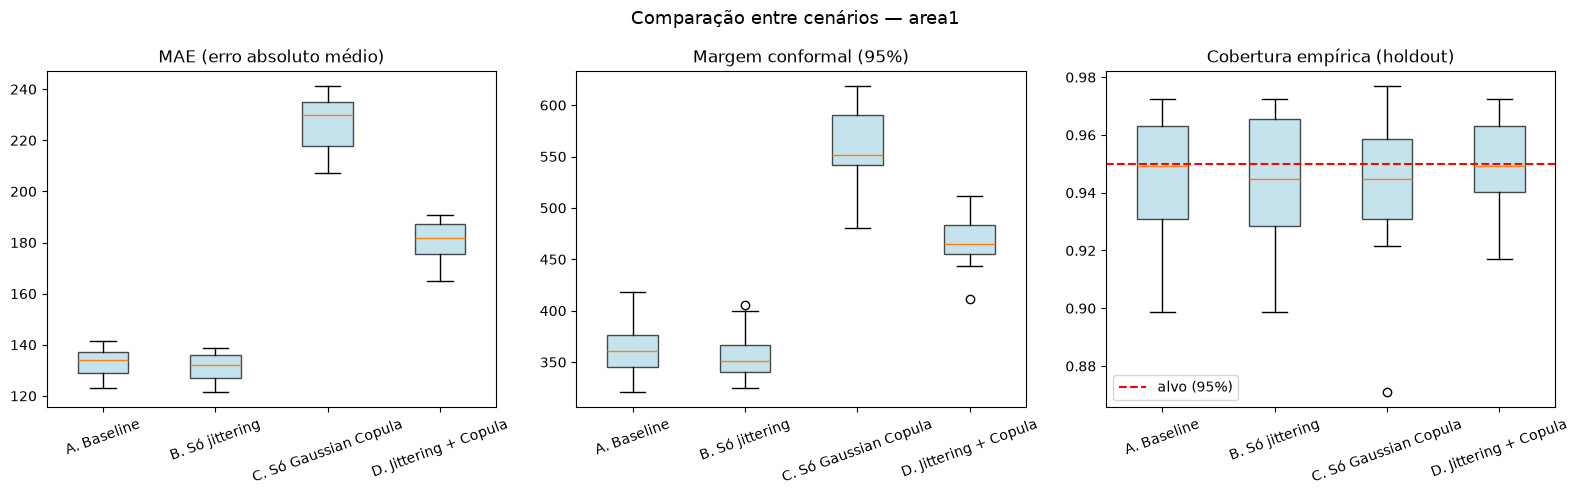

In [25]:
NOMES_CENARIOS = {
    "A_baseline": "A. Baseline",
    "B_jittering": "B. Só jittering",
    "C_sdv_copula": "C. Só Gaussian Copula",
    "D_combinado": "D. Jittering + Copula",
}
ORDEM_CENARIOS = ["A_baseline", "B_jittering", "C_sdv_copula", "D_combinado"]

df_todos = pd.concat([resultados_A, resultados_B, resultados_C, resultados_D], ignore_index=True)
df_todos.to_csv(OUTPUT_DIR / f"resultados_todos_cenarios_{AREA}.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
labels = [NOMES_CENARIOS[c] for c in ORDEM_CENARIOS]
metricas = [
    ("mae", "MAE (erro absoluto médio)"),
    ("margem", "Margem conformal (95%)"),
    ("cobertura_holdout", "Cobertura empírica (holdout)"),
]
for ax, (metrica, titulo) in zip(axes, metricas):
    dados = [df_todos[df_todos["cenario"] == c][metrica].values for c in ORDEM_CENARIOS]
    bp = ax.boxplot(dados, patch_artist=True)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels, rotation=20)
    for box in bp["boxes"]:
        box.set(facecolor="lightblue", alpha=0.7)
    ax.set_title(titulo)
    if metrica == "cobertura_holdout":
        ax.axhline(0.95, color="red", linestyle="--", label="alvo (95%)")
        ax.legend()

plt.suptitle(f"Comparação entre cenários — {AREA}", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"comparacao_cenarios_{AREA}.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
baseline = df_todos[df_todos["cenario"] == "A_baseline"].sort_values("seed")
linhas = []
for cenario in ["B_jittering", "C_sdv_copula", "D_combinado"]:
    comparado = df_todos[df_todos["cenario"] == cenario].sort_values("seed")
    for metrica in ["mae", "margem"]:
        estat, p = wilcoxon(baseline[metrica].values, comparado[metrica].values)
        media_baseline = baseline[metrica].mean()
        media_cenario = comparado[metrica].mean()
        linhas.append({
            "cenario": NOMES_CENARIOS[cenario],
            "metrica": metrica,
            "media_baseline": round(media_baseline, 2),
            "media_cenario": round(media_cenario, 2),
            "reducao_pct": round((1 - media_cenario / media_baseline) * 100, 2),
            "p_valor": round(p, 5),
            "significativo_p<0.05": p < 0.05,
        })

tabela_significancia = pd.DataFrame(linhas)
tabela_significancia.to_csv(OUTPUT_DIR / f"tabela_significancia_{AREA}.csv", index=False)
tabela_significancia

,cenario,metrica,media_baseline,media_cenario,reducao_pct,p_valor,significativo_p<0.05
0,B. Só jittering,mae,133.04,131.06,1.49,0.00006,True
1,B. Só jittering,margem,361.79,356.21,1.54,0.03015,True
2,C. Só Gaussian Copula,mae,133.04,226.95,-70.59,0.00006,True
3,C. Só Gaussian Copula,margem,361.79,559.04,-54.52,0.00006,True
4,D. Jittering + Copula,mae,133.04,180.39,-35.59,0.00006,True
5,D. Jittering + Copula,margem,361.79,468.68,-29.55,0.00006,True


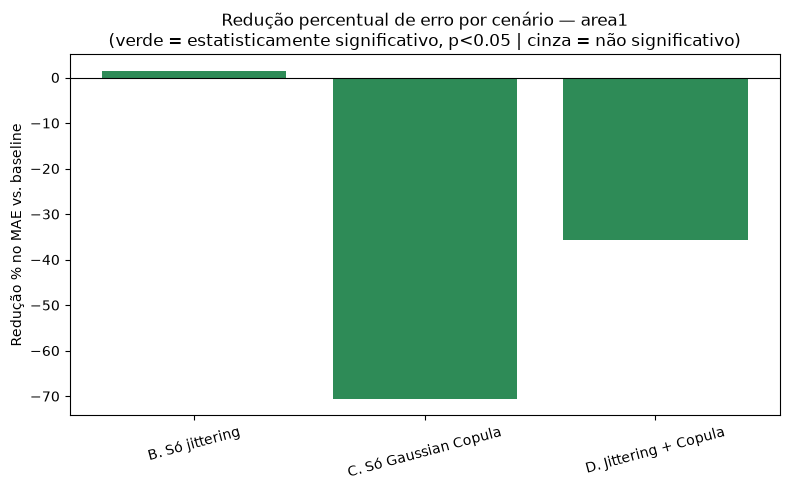

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
tabela_mae = tabela_significancia[tabela_significancia["metrica"] == "mae"]
cores = ["seagreen" if sig else "lightgray" for sig in tabela_mae["significativo_p<0.05"]]

ax.bar(tabela_mae["cenario"], tabela_mae["reducao_pct"], color=cores)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Redução % no MAE vs. baseline")
ax.set_title(
    f"Redução percentual de erro por cenário — {AREA}\n"
    "(verde = estatisticamente significativo, p<0.05 | cinza = não significativo)"
)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"reducao_percentual_{AREA}.png", dpi=150, bbox_inches="tight")
plt.show()